In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

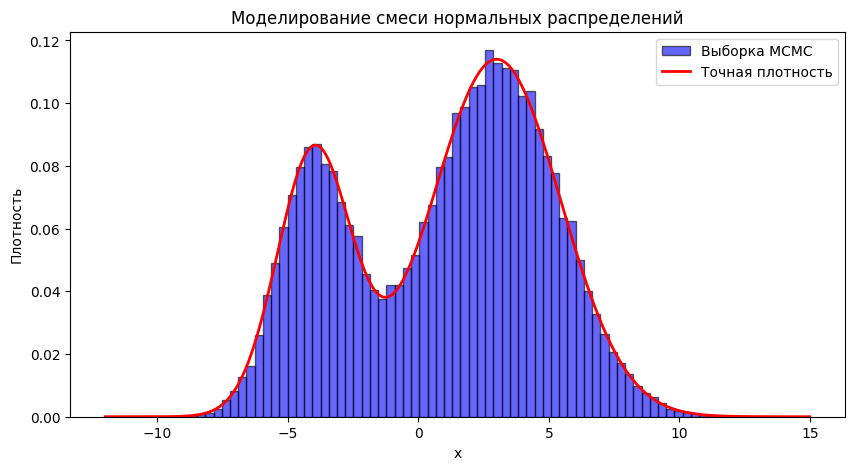

In [2]:
np.random.seed(42)

#Плотность смеси нормальных распределений
def p(x):
    return (0.3 * norm.pdf(x, -4, np.sqrt(2)) +
            0.7 * norm.pdf(x, 3, np.sqrt(6)))

#Алгоритм Метрополиса
def metropolis(start, sigma, N, burn=0):
    current = start
    current_p = p(current)
    samples = np.zeros(N)

    for i in range(N):
        #Предлагаем новое состояние
        proposed = current + sigma * np.random.randn()
        proposed_p = p(proposed)

        #Вероятность перехода
        alpha = min(1, proposed_p / current_p)

        if np.random.rand() < alpha:
            current = proposed
            current_p = proposed_p

        samples[i] = current

    return samples[burn:]

#Параметры
N = 100000
burn = 5000
sigma = 4
start = 0

samples = metropolis(start, sigma, N, burn)

#Строим гистограмму и точную плотность
x = np.linspace(-12, 15, 1000)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('xkcd:white')

ax.hist(samples, bins=70, density=True, alpha=0.6,
        color='b', edgecolor='black', label='Выборка MCMC')

ax.plot(x, p(x), 'r-', lw=2, label='Точная плотность')

ax.set_title('Моделирование смеси нормальных распределений')
ax.set_xlabel('x')
ax.set_ylabel('Плотность')
ax.legend()
plt.show()

Точное математическое ожидание: 1.142857
Выборочное среднее: 1.137980


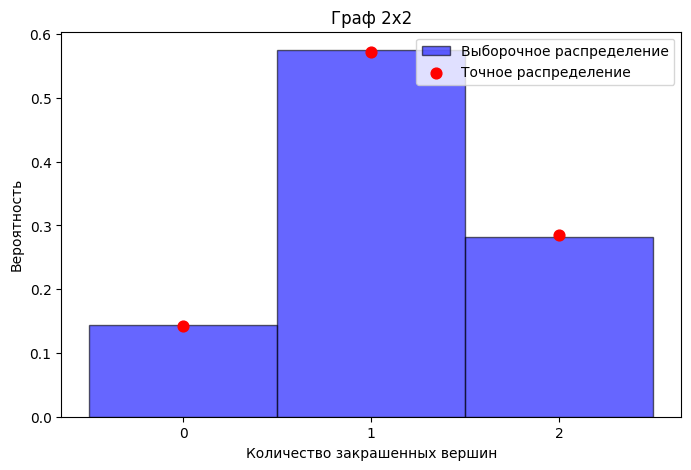

In [5]:
np.random.seed(42)

def graph_mcmc(n, N, burn=0):
    #Создаем граф
    graph = np.zeros((n + 2, n + 2), dtype=int)
    samples = np.zeros(N, dtype=int)
    count = 0

    #Генерируем координаты случайных вершин
    rows = np.random.randint(1, n + 1, N)
    cols = np.random.randint(1, n + 1, N)
    u = np.random.rand(N)

    for k in range(N):
        i, j = rows[k], cols[k]

        #Меняем цвет с вероятностью 1/2, если это допустимо
        if u[k] < 0.5:

            #Закрашенную вершину можно обесцветить
            if graph[i, j] == 1:
                graph[i, j] = 0
                count -= 1

            #Проверяем, что все соседние вершины белые
            elif (graph[i-1, j] + graph[i+1, j] +
                  graph[i, j-1] + graph[i, j+1] == 0):

                graph[i, j] = 1
                count += 1

        #Запоминаем количество закрашенных вершин
        samples[k] = count

    return samples[burn:]
#Проверяем алгоритм на графе 2x2
samples2 = graph_mcmc(2, 100000, burn=1000)

print(f"Точное математическое ожидание: {8/7:.6f}")
print(f"Выборочное среднее: {np.mean(samples2):.6f}")

#Точное распределение числа закрашенных вершин
x = np.arange(3)
probs = np.array([1, 4, 2]) / 7

#Строим гистограмму
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('xkcd:white')

ax.hist(samples2, bins=np.arange(4) - 0.5,
        density=True, alpha=0.6, color='b',
        edgecolor='black', label='Выборочное распределение')

ax.scatter(x, probs, color='red', s=60,
           zorder=3, label='Точное распределение')

ax.set_xticks(x)
ax.set_title('Граф 2x2')
ax.set_xlabel('Количество закрашенных вершин')
ax.set_ylabel('Вероятность')
ax.legend()
plt.show()

Среднее количество закрашенных вершин: 23.6383
Выборочная дисперсия: 8.6956


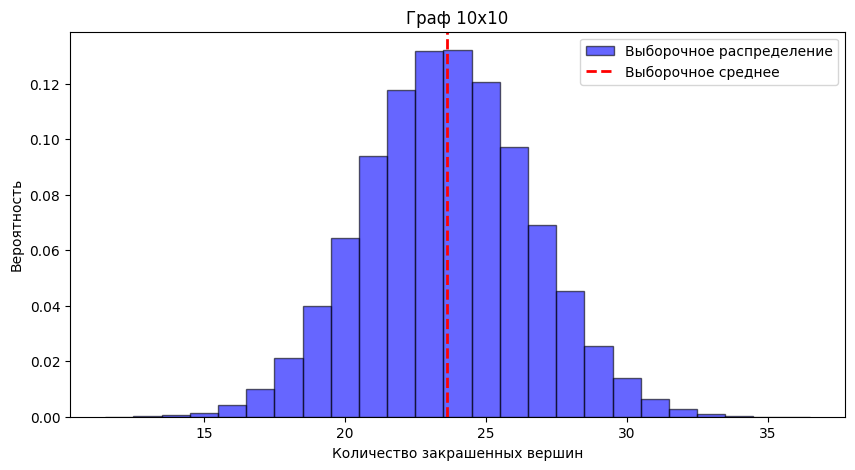

In [6]:
#Граф 10x10
N = 500000
burn = 10000

samples10 = graph_mcmc(10, N, burn)

print(f"Среднее количество закрашенных вершин: {np.mean(samples10):.4f}")
print(f"Выборочная дисперсия: {np.var(samples10):.4f}")

#Строим распределение количества закрашенных вершин
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('xkcd:white')

bins = np.arange(samples10.min(), samples10.max() + 2) - 0.5

ax.hist(samples10, bins=bins, density=True,
        alpha=0.6, color='b', edgecolor='black',
        label='Выборочное распределение')

ax.axvline(np.mean(samples10), color='red',
           linestyle='--', lw=2, label='Выборочное среднее')

ax.set_title('Граф 10x10')
ax.set_xlabel('Количество закрашенных вершин')
ax.set_ylabel('Вероятность')
ax.legend()
plt.show()